# Implied Odds: a guided tour of the code

This notebook walks through the project layer by layer. Each section explains what a part of the code does, then
runs it so you can see it work. Run the cells top to bottom (Shift+Enter). Nothing here downloads data or changes
files except the small charts it draws.

**The layers**

1. **Data** (`collect/`): pulls Kalshi, Polymarket, SPX options and ETF prices.
2. **Robustness** (`robustness/`): decides whether a backtest result is real or luck.
3. **Strategy discovery** (`strategies/`, `research/strategy_discovery.py`): searches 2,120 rules and shows what overfitting does.
4. **Calibration** (`research/calibration.py`): are Kalshi's prices honest probabilities?
5. **Option-implied fair value** (`implied/`): Breeden–Litzenberger turns option prices into probabilities.
6–8. Cross-venue, price discovery and the model come later and reuse the same pieces.

In [1]:
import os, sys
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
os.chdir(ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
print("project root:", ROOT)

project root: /Users/tavelarocque/CODE/implied-odds


## 0. The tests come first

Before trusting any result, the tools that produce it have to pass their own tests. `run_tests.py` runs all of
them. If any line says FAIL, stop and fix that before reading further.

In [2]:
import subprocess
print(subprocess.run([sys.executable, "run_tests.py"], capture_output=True, text=True).stdout)

PASS  tests.test_breeden_litzenberger          2.4s
PASS  tests.test_no_lookahead                  1.3s
PASS  tests.test_overfitting                   0.5s

all tests passed



## 2. The robustness layer

Open `robustness/overfitting.py` alongside this. The key idea: if you test many strategies that have **no** edge,
the best one still looks good by luck. The deflated Sharpe ratio raises the bar to the Sharpe you would expect
from the luckiest of N tries.

Below, 400 strategies of pure noise. Watch the naive test get fooled and the deflated one not.

In [3]:
from robustness import sharpe, probabilistic_sharpe, deflated_sharpe, pbo_cscv
rng = np.random.default_rng(1)
noise = rng.normal(0, 0.01, (2520, 400))                 # 10 years x 400 strategies, no edge at all
srs = noise.mean(0) / noise.std(0, ddof=1)               # per-day Sharpe of each
best = int(np.argmax(srs))
dsr, sr0 = deflated_sharpe(noise[:, best], srs)
print(f"best of 400 noise strategies: annualized Sharpe {sharpe(noise[:, best]):.2f}")
print(f"naive probabilistic Sharpe:   {probabilistic_sharpe(noise[:, best]):.3f}   <- fooled")
print(f"deflated Sharpe:              {dsr:.3f}   <- not fooled")
print(f"probability of backtest overfitting: {pbo_cscv(noise, n_blocks=10)['pbo']:.2f}  (about 0.5 means pure luck)")

best of 400 noise strategies: annualized Sharpe 0.89
naive probabilistic Sharpe:   0.998   <- fooled
deflated Sharpe:              0.422   <- not fooled
probability of backtest overfitting: 0.50  (about 0.5 means pure luck)


**Try it:** add a real edge to five strategies with `noise[:, :5] += 0.001` and rerun the cell. The deflated Sharpe
should jump toward 1 and the overfitting probability toward 0.

## 3. Strategy discovery

`strategies/rules.py` defines four families of classic rules. Each returns a signal of +1 (long), −1 (short) or 0,
using only prices up to that day. `strategies/backtest.py` shifts every signal by one day before it earns a return,
which is what makes the backtest honest; `tests/test_no_lookahead.py` proves it by scrambling future prices and
checking that no past position moves.

54 rules, for example: ['mom_5_0', 'mom_10_0', 'mom_10_5', 'mom_20_0'] ... ['bo_55', 'bo_100', 'bo_252']


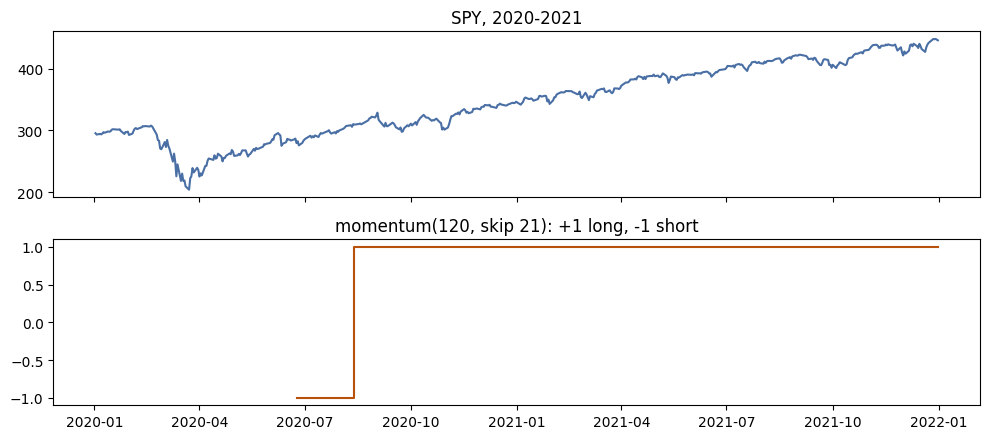

In [4]:
from strategies import rules, momentum
names = [n for n, _ in rules()]
print(len(names), "rules, for example:", names[:4], "...", names[-3:])
px = pd.read_csv("data/history/etf/prices.csv.gz", index_col=0, parse_dates=True)
spy = px["SPY"].loc["2020":"2021"]
sig = momentum(spy, 120, 21)
fig, ax = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
ax[0].plot(spy, color="#4a6fa5"); ax[0].set_title("SPY, 2020-2021")
ax[1].step(sig.index, sig, color="#b8520a", where="post"); ax[1].set_title("momentum(120, skip 21): +1 long, -1 short")
fig.tight_layout()

The full study (`research/strategy_discovery.py`) runs every rule on ten ETFs, ranks them on 2000–2012 and tests
them on 2013–2026. Its saved result:

      is_mean  oos_mean  oos_p10  oos_p90   gap
k                                              
1        0.16      0.22    -0.21     0.65 -0.07
3        0.40      0.30    -0.11     0.68  0.10
10       0.57      0.25    -0.16     0.64  0.33
30       0.71      0.26    -0.14     0.62  0.46
100      0.84      0.24    -0.09     0.56  0.61
300      0.94      0.21    -0.09     0.50  0.73
1000     1.02      0.05    -0.09     0.27  0.98


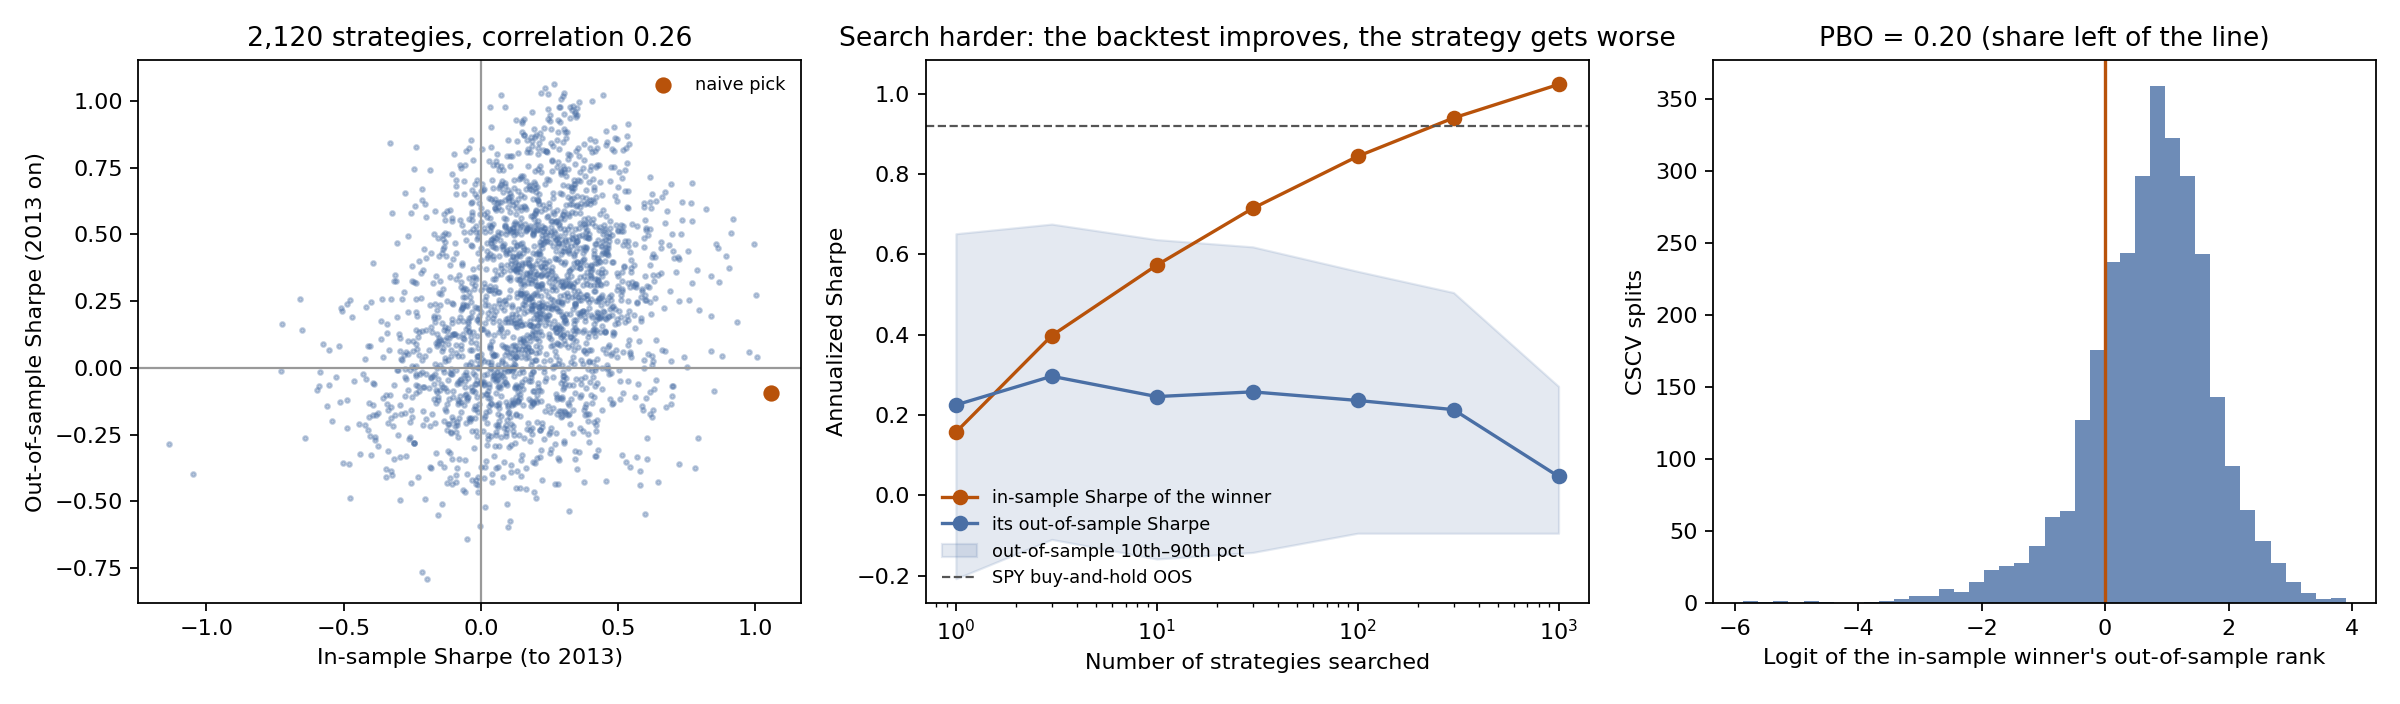

In [5]:
curve = pd.read_csv("research/output/strategy_discovery/search_curve.csv", index_col=0)
print(curve.round(2).to_string())
from IPython.display import Image
Image("research/output/strategy_discovery/overfitting.png")

Read the middle chart: as the search grows, the winner's in-sample Sharpe climbs toward 1, while its out-of-sample
Sharpe falls toward zero. Searching harder made the backtest better and the strategy worse.

## 5. Breeden–Litzenberger

Open `implied/bl.py`. The chain of steps:

1. `estimate_forward` regresses call minus put on strike (put–call parity) to get the forward price and discount factor.
2. Each out-of-the-money option becomes a Black implied volatility.
3. `fit_surface` fits a smooth SVI smile, first in volatility space, then refined in **price** space weighted by
   each quote's spread, because cheap options have noisy volatilities.
4. `Surface.prob_above(K)` is minus the discounted slope of the call price curve; a Kalshi range is a difference of two.

First, a check where we know the answer: prices generated from a known smile.

P(7600 < S <= 7650): true 0.0973, recovered 0.0968
P(7700 < S <= 7725): true 0.1817, recovered 0.1830
P(7800 < S <= 7900): true 0.0382, recovered 0.0377


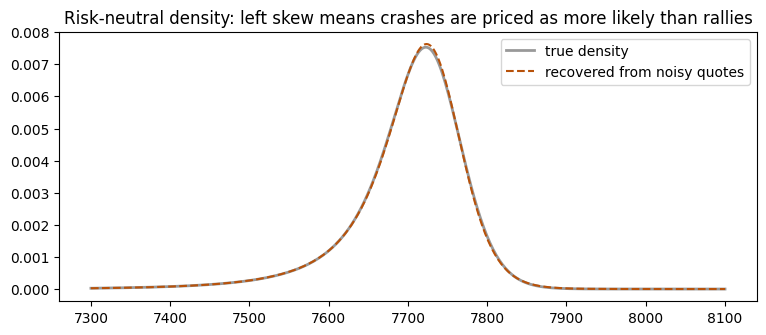

In [6]:
from implied import black_call, black_put, fit_surface, Surface
F, T, DF = 7700.0, 5 / 365, 0.9995
true = Surface(F, DF, T, (0.00002, 0.004, -0.75, 0.002, 0.012), (-1, 1))
K = np.arange(7000, 8405, 5.0)
noise = lambda x: np.maximum(x + rng.uniform(-0.15, 0.15, x.shape), 0.05)
fit = fit_surface(K, noise(black_call(F, K, T, true.sigma(K), DF)), noise(black_put(F, K, T, true.sigma(K), DF)), T, spot_guess=7690)
for lo, hi in [(7600, 7650), (7700, 7725), (7800, 7900)]:
    print(f"P({lo} < S <= {hi}): true {true.prob_between(lo, hi):.4f}, recovered {fit.prob_between(lo, hi):.4f}")
grid = np.linspace(7300, 8100, 400)
plt.figure(figsize=(9, 3.5))
plt.plot(grid, true.density(grid), label="true density", lw=2, color="#999")
plt.plot(grid, fit.density(grid), "--", label="recovered from noisy quotes", color="#b8520a")
plt.title("Risk-neutral density: left skew means crashes are priced as more likely than rallies"); plt.legend(); plt.show()

Now the real thing: Friday's SPX options against Kalshi's quotes for the same days
(`research/fair_value_snapshot.py`). Weekend Kalshi order books are very wide, so this is a pipeline check, not
evidence; weekday snapshots start Monday.

             event          range  bid  ask  p_options  inside_spread
KXINX-26OCT05H1600 7,625 to 7,650 0.00 0.16      0.033           True
KXINX-26OCT05H1600 7,650 to 7,675 0.01 0.20      0.064           True
KXINX-26OCT05H1600 7,675 to 7,700 0.05 0.20      0.116           True
KXINX-26OCT05H1600 7,700 to 7,725 0.07 0.20      0.178           True
KXINX-26OCT05H1600 7,725 to 7,750 0.04 0.20      0.217          False
KXINX-26OCT05H1600 7,750 to 7,775 0.01 0.20      0.192           True
KXINX-26OCT05H1600 7,775 to 7,800 0.06 0.20      0.115           True
KXINX-26OCT05H1600 7,800 to 7,825 0.02 0.19      0.043           True
KXINX-26OCT09H1600 7,600 to 7,625 0.00 0.19      0.036           True
KXINX-26OCT09H1600 7,625 to 7,650 0.01 0.16      0.047           True
KXINX-26OCT09H1600 7,650 to 7,675 0.02 0.10      0.060           True
KXINX-26OCT09H1600 7,675 to 7,700 0.02 0.11      0.074           True
KXINX-26OCT09H1600 7,700 to 7,725 0.03 0.13      0.088           True
KXINX-26OCT09H1600 7

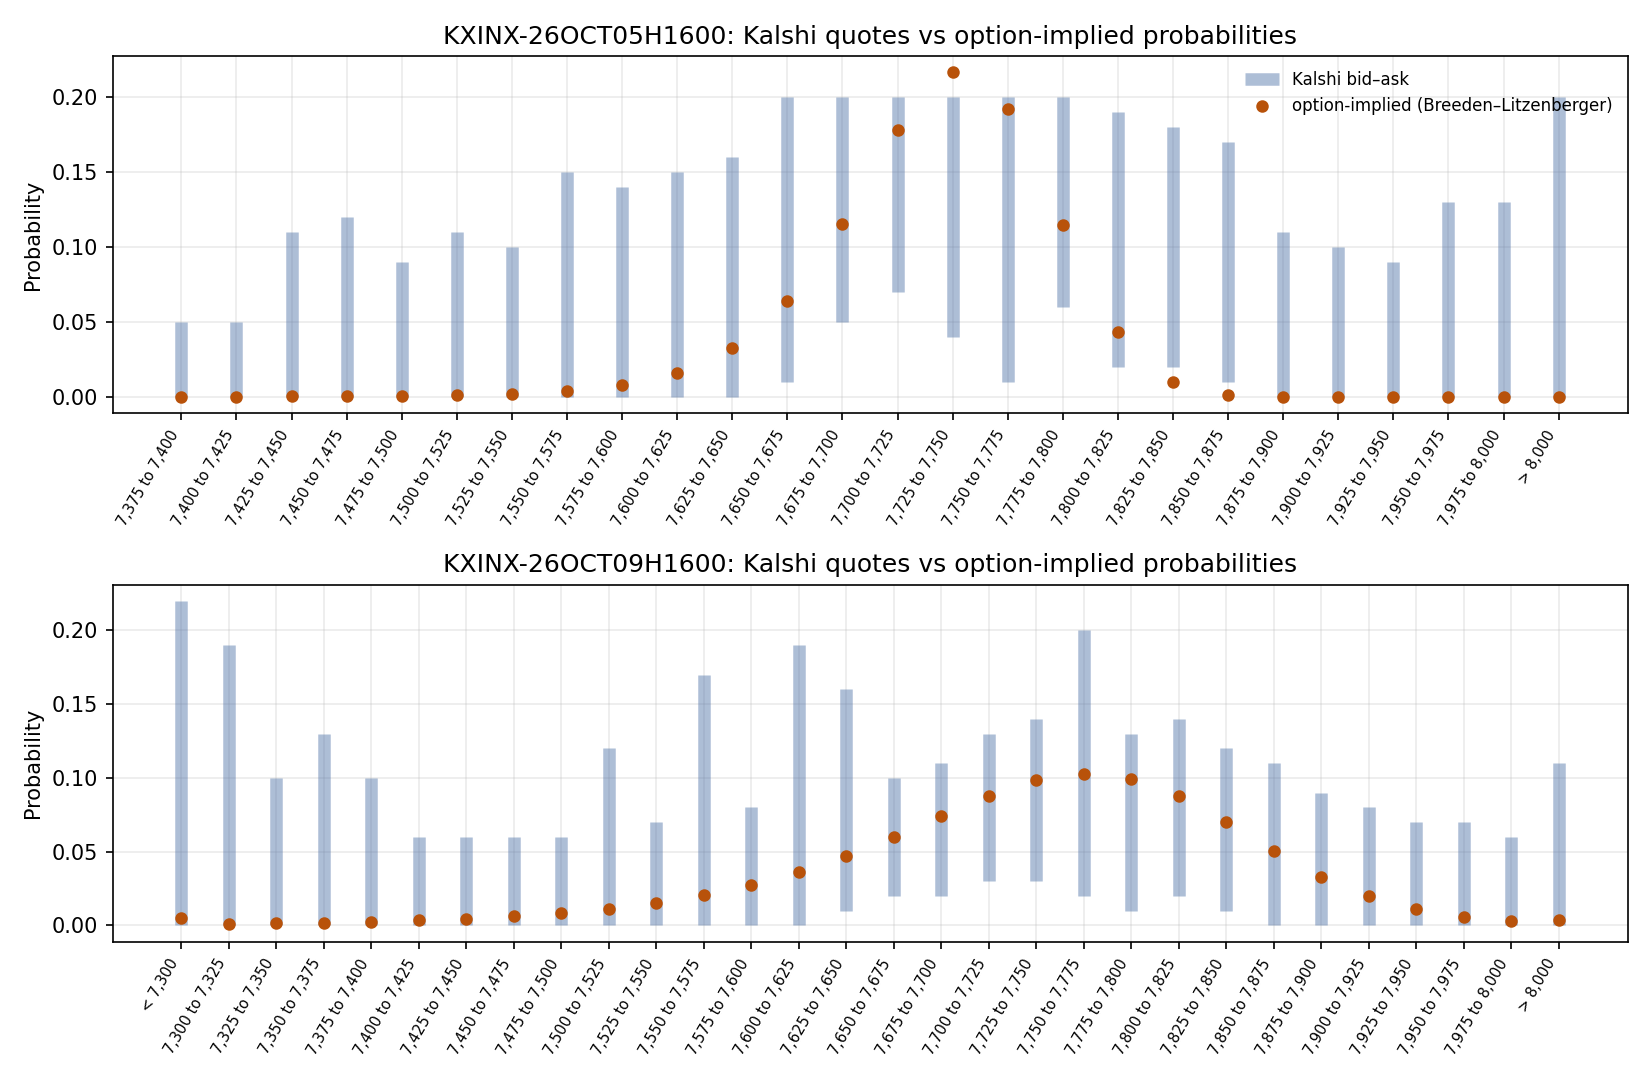

In [7]:
import glob
csvs = sorted(glob.glob("research/output/fair_value/*.csv"))
if csvs:
    fv = pd.read_csv(csvs[-1])
    print(fv[["event", "range", "bid", "ask", "p_options", "inside_spread"]].query("p_options > 0.03").round(3).to_string(index=False))
    display(Image(sorted(glob.glob("research/output/fair_value/*.png"))[-1]))
else:
    print("run: python3 research/fair_value_snapshot.py")

## 1 and 4. The data and the calibration study

`collect/` holds every downloader. Kalshi's history is saved under `data/history/kalshi/`: one line per settled
contract, with its strike range and result. A peek:

In [8]:
import gzip, json
with gzip.open("data/history/kalshi/markets_KXINX.jsonl.gz", "rt") as f:
    mk = pd.DataFrame(json.loads(l) for l in f)
print(f"{len(mk):,} contracts across {mk.event_ticker.nunique():,} trading days")
mk[["ticker", "strike_type", "floor_strike", "cap_strike", "result", "close_time"]].tail(6)

22,688 contracts across 1,131 trading days


,ticker,strike_type,floor_strike,cap_strike,result,close_time
22682,KXINX-26OCT02H1600-B7487,between,7475.0,7499.9999,no,2026-10-02T20:00:00Z
22683,KXINX-26OCT02H1600-B7462,between,7450.0,7474.9999,no,2026-10-02T20:00:00Z
22684,KXINX-26OCT02H1600-B7437,between,7425.0,7449.9999,no,2026-10-02T20:00:00Z
22685,KXINX-26OCT02H1600-B7412,between,7400.0,7424.9999,no,2026-10-02T20:00:00Z
22686,KXINX-26OCT02H1600-B7387,between,7375.0,7399.9999,no,2026-10-02T20:00:00Z
22687,KXINX-26OCT02H1600-B7362,between,7350.0,7374.9999,no,2026-10-02T20:00:00Z


`research/calibration.py` reads each contract's price 1, 3, 6 and 24 hours before the close from the hourly candles
and checks whether 20-cent contracts really win 20% of the time. It uses only data before the locked holdout date
in `research/config.py`. Run it once the hourly download finishes:

```
python3 research/calibration.py
```

## Where to go next

- Read one file at a time, in this order: `robustness/overfitting.py`, `strategies/backtest.py`, `implied/bl.py`,
  `research/calibration.py`.
- Each research script is split into `# %%` cells, so VS Code can run it like this notebook.
- Change something, then run `python3 run_tests.py`. If the tests still pass, you didn't break the foundations.